# 3D Dip Transform Simulator
Date: 15.10.2026


Experimental notebook, testing various packages, shapes, methods with lots of visualizations along the way to measure progress


In [2]:
#accumulated dependencies

#%pip install trimesh plotly numpy
#%pip install --upgrade nbformat
#%pip install pillow
#%pip install scipy
#%pip install matplotlib
#%pip install ipywidgets


In [38]:
import trimesh
import numpy as np
import scipy

import plotly.graph_objects as go
import matplotlib.pyplot as plt

import ipywidgets as widgets
from IPython.display import display

In [4]:
## basic shapes for testing
sphere = trimesh.creation.icosphere(
    subdivisions=3,
    radius=20
)

cube= trimesh.creation.box(
    extents=[10,10,10]
)

icosahedron = trimesh.creation.icosphere(
    subdivisions=0,
    radius=20
)


##visualize with pltly
def see_mesh(mesh, withgrid = True, opacity_=0.8):
    vertices=mesh.vertices
    faces=mesh.faces

    fig=go.Figure(
        data=[go.Mesh3d(
            x=vertices[:, 0],
            y=vertices[:, 1],
            z=vertices[:, 2],
            i=faces[:,0],
            j=faces[:,1],
            k=faces[:,2],
            opacity=opacity_)
            ]
    )

    fig.update_layout(
        scene=dict(
            aspectmode="data",
            xaxis=dict(title="x",showgrid=withgrid, visible=withgrid),
            yaxis=dict(title="y",showgrid=withgrid, visible=withgrid),
            zaxis=dict(title="z",showgrid=withgrid, visible=withgrid)

        ),
        width=700,
        height=550
    )

    fig.show()


In [5]:
# see_mesh(sphere, False)
# see_mesh(icosahedron, False)
# see_mesh(cube)


In [6]:
#visualize with trimesh
# sphere.show()
# cube.show()

## Step 1
* Input: Voxelization resolution, 
* n number of orientations(# of dips?)
* Select standard shape (sphere, cube, tetrahedron) 
* Generalize: Input triangle mesh (.obj)


In [7]:
mesh_input = trimesh.load("pisa.obj", force="mesh")
see_mesh(mesh_input, False)

In [8]:
# variable shape
shape = mesh_input
see_mesh(shape)

In [9]:
#mesh properties
print("vertices     : ", len(shape.vertices))
print("faces        : ", len(shape.faces))
print("volume       : ", shape.volume)
print("surface area : ", shape.area)
print("bounds       : ", shape.bounds)
print("watertight   : ", shape.is_watertight)

vertices     :  67864
faces        :  90000
volume       :  0.7432486316632936
surface area :  7.78386884937115
bounds       :  [[-0.119144 -1.256318 -7.922876]
 [ 1.008152  1.139969 -6.825635]]
watertight   :  False


## Step2: Voxelization 3D space

In [10]:
#voxelize with trimesh (only able with watertight meshes)

res=0.05  #voxel resolution
voxel_grid = shape.voxelized(pitch=res).fill()
voxels= voxel_grid.matrix
print(voxels.shape)
print(voxels.dtype)

print("actual   volume : ", shape.volume)
print("estimate volume : ", np.sum(voxels) * res ** 3)


(23, 49, 22)
bool
actual   volume :  0.7432486316632936
estimate volume :  1.0001250000000002


In [11]:
#voxels

In [12]:
## visualize
def see_voxels(voxel_grid, size=res):
    points = voxel_grid.points
    fig=go.Figure(
        data=[go.Scatter3d(
            x=points[:, 0],
            y=points[:, 1],
            z=points[:, 2],
            mode="markers", 
            marker=dict(
                size=size, 
                opacity=0.6
                )
            )]
    )

    fig.update_layout(
        scene=dict(
            aspectmode="data",
        ),
        width=700,
        height=550
    )

    fig.show()

see_voxels(voxel_grid, 10)

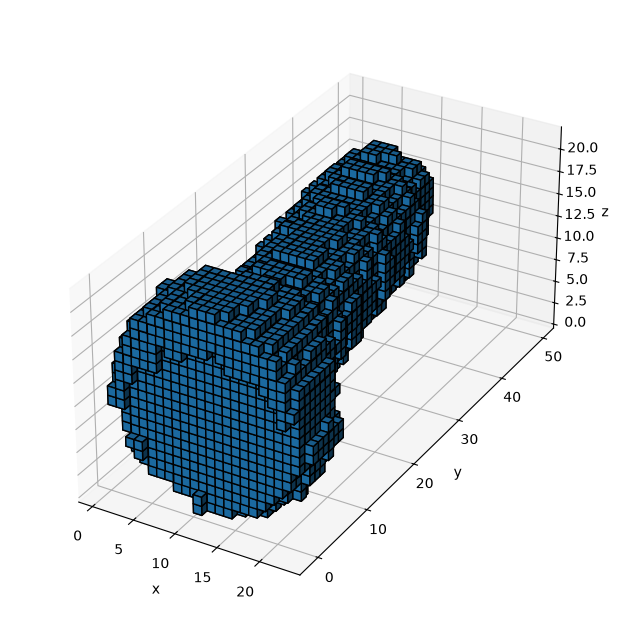

In [13]:
## AI help

def see_voxel_cubes(voxels):
    fig = plt.figure(figsize=(8, 8))
    ax = fig.add_subplot(1,1,1, projection="3d")
    ax.voxels(
        voxels,
        edgecolor="black"
    )
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.set_zlabel("z")
    ax.set_box_aspect(voxels.shape)
    plt.show()
see_voxel_cubes(voxels)

## Step3: Generate orientations

Orientations:
theta: vertical angle, wrt z-axis
phi: horizontal angle, wrt z-axis 


for each orentation, project each voxel onto the dipping direction
* d_i = x_i * n

In [14]:
#calculate normal direction from orientations phi,theta (deg)
def get_normal(theta, phi):
    theta=np.radians(theta) #conver to radians
    phi=np.radians(phi)

    #calculate vector
    nx=np.sin(theta) * np.cos(phi)
    ny=np.sin(theta)*np.sin(phi)
    nz=np.cos(theta)
    return np.array([nx, ny, nz])

In [15]:
points = voxel_grid.points # occupied voxel positions 
print("Voxel Density:", len(points), "/", voxel_grid.shape[0]**3 , "=", len(points)/voxel_grid.shape[0]**3)

#calculate projections
theta=45
phi=30
n=get_normal(theta, phi)
d = points @ n

d.shape

Voxel Density: 8001 / 12167 = 0.6575984219610421


(8001,)

# Step4 : Simulate dipping
* visualize water wrt dip and orientation

In [16]:
## water_h signed position of water wrt to the origin
def make_water_plane(n, water_h, size=30):

    # Pick a vector that is not parallel to normal
    reference = np.array([0.0, 0.0, 1.0])

    if abs(np.dot(n, reference)) > 0.9:
        reference = np.array([1.0, 0.0, 0.0])

    # Two perpendicular directions inside the plane
    u = np.cross(n, reference)
    u = u / np.linalg.norm(u)
    v = np.cross(n, u)
    # note u and v define the surface of the water plane

    # Center of the plane
    center = water_h * n

    # Four corners
    corners = np.array([
        center - size*u - size*v,
        center + size*u - size*v,
        center + size*u + size*v,
        center - size*u + size*v
    ])

    return corners

In [17]:
make_water_plane(n, 20, size=30)

array([[-21.12372436,  22.44522821,  35.35533906],
       [  8.87627564, -29.51629602,  35.35533906],
       [ 45.61862178,  -8.30309258,  -7.07106781],
       [ 15.61862178,  43.65843164,  -7.07106781]])

In [18]:
def water_visual(points, theta, phi, water_h, res=res):
    n = get_normal(theta, phi)
    d = points @ n
    underwater = d <= water_h #underwater if projection is less than water height
    submerged = points[underwater]
    not_submerged = points[~underwater]
    fig=go.Figure()

       #voxels that are not underwater
    if len(not_submerged) > 0:
        fig.add_trace(go.Scatter3d(
            x=not_submerged[:, 0],
            y=not_submerged[:, 1],
            z=not_submerged[:, 2],
            mode="markers",
            marker=dict(size=5, color="yellow", opacity=0.5),
            name="Above water"
        ))

    #submerged voxels
    if len(submerged) > 0:
        fig.add_trace(go.Scatter3d(
            x=submerged[:, 0],
            y=submerged[:, 1],
            z=submerged[:, 2],
            mode="markers",
            marker=dict(size=5, color="blue", opacity=0.7),
            name="Underwater"
        ))
    # create water plane
    size = np.linalg.norm(voxel_grid.shape) * res
    corners = make_water_plane(n, water_h,size)

    fig.add_trace(go.Mesh3d(
        x=corners[:, 0],
        y=corners[:, 1],
        z=corners[:, 2],
        i=[0, 0],
        j=[1, 2],
        k=[2, 3],
        color="lightblue",
        opacity=0.5
    ))

    fig.update_layout(
        title=f"theta={theta}, phi={phi}, water height={water_h}",
        scene=dict(
            aspectmode="data",
            xaxis_title="x",
            yaxis_title="y",
            zaxis_title="z"
        ),
        width=700,
        height=550
    )

    fig.show()


In [19]:
water_visual(points, 0, 0, -7)

### calculate displaced volume
displace volume V (water_height) =
sum (1[projection <= water_height] * voxel volume) 

In [ ]:
def displaced_volume(points, theta, phi, water_h, res=res):
    n = get_normal(theta, phi)
    d = points @ n
    underwater = d <= water_h #underwater if projection is less than water height
    n_submerged = np.sum(underwater)
    #not_submerged = points[~underwater]

    voxel_volume = res ** 3
    volume = n_submerged * voxel_volume
    return volume

In [21]:
displaced_volume(points, 45, 90, 0, res=res)


np.float64(1.0001250000000002)

In [22]:
#total voxelized volume
np.sum(voxels) * res ** 3


np.float64(1.0001250000000002)

## simulate 1 full dip

In [23]:
n = get_normal(theta=45, phi=30)
d = points @ n
n_heights = 10

#pad so shape is gaurenteed complete submerge
water_h = np.linspace(d.min() - res, d.max() + res, n_heights) 
water_h

volumes=[]
for w in water_h :
    volume = displaced_volume(points, theta, phi, w, res)
    volumes.append(volume)
volumes = np.array(volumes)
volumes 

array([0.      , 0.01175 , 0.064125, 0.15325 , 0.30925 , 0.528375,
       0.76225 , 0.91675 , 0.987125, 1.000125])

In [24]:
water_h

array([-5.92845972, -5.75498853, -5.58151735, -5.40804617, -5.23457498,
       -5.0611038 , -4.88763262, -4.71416143, -4.54069025, -4.36721906])

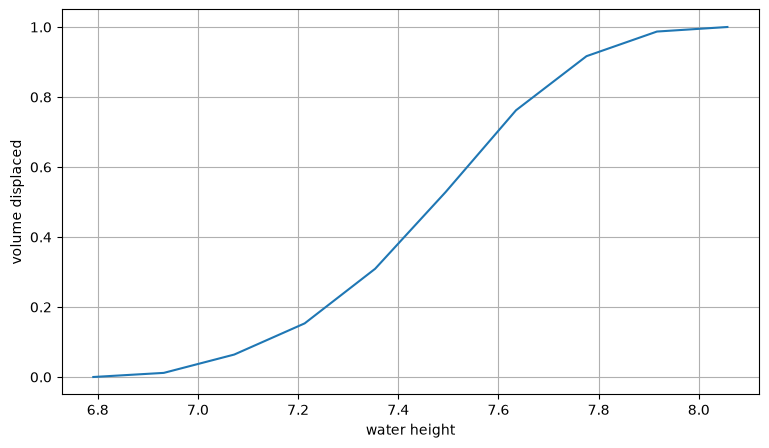

In [39]:
plt.figure(figsize=(9, 5))

plt.plot(water_h, volumes)
plt.xlabel("water height")
plt.ylabel("volume displaced")

plt.grid(True)
plt.show()

In [26]:
def virtual_dip(points, theta, phi, res=res):

    n = get_normal(theta, phi)
    d = points @ n
    #pad so shape is gaurenteed complete submerge
    #water_h = np.linspace(d.min() - res, d.max() + res, n_heights) 

    slider = widgets.FloatSlider(
        value=d.min() - res,
        min=d.min() - res,
        max=d.max() - res,
        step=res,
        continuous_update=True
    )

    def update(water_h):
        water_visual(points, theta, phi, water_h)
        volume = displaced_volume(points, theta, phi, water_h, res)
        print("displaced volume:", volume)

    widgets.interact(update, water_h=slider)



virtual_dip(points,theta=0,phi=90)

interactive(children=(FloatSlider(value=-7.95, description='water_h', max=-6.9, min=-7.95, step=0.05), Output(…

## simulate n number of dips
1. input n_dips, n_heights
2. calculate normal vector
3. voxel projectoins
4. dipping heights (simulate change in water)
5. displaced volume at each water height
6. create output [theta, phi, h_water, displaced_volume]

In [27]:
#how best to uniformly distribution phi and theta slices? 
#asked AI, and it recommended using a "fibonacci sphere"
def generate_orientations(n_dips):
    indices = np.arange(n_dips)
    # Approximately uniform distribution on a sphere
    z = 1 - 2 * (indices + 0.5) / n_dips
    golden_angle = np.pi * (3 - np.sqrt(5))
    phi = indices * golden_angle
    theta = np.arccos(z)

    # Convert to degrees
    theta = np.degrees(theta)
    phi = np.degrees(phi) % 360

    return np.column_stack((theta, phi))

In [48]:
generate_orientations(100).shape

(100, 2)

In [29]:
def dip_simulator(points, orientations, n_heights):

    outputs=[]
    for i, (theta, phi) in enumerate(orientations):
        n = get_normal(theta, phi)
        d = points @n
        
        water_h = np.linspace(d.min() - res, d.max() + res, n_heights)
        #count the number submerged at each water height
        counts = np.array([np.count_nonzero(d <= h) for h in water_h])
        vol_h = counts * res**3

        dip_output = np.column_stack([
            np.full(n_heights, i+1),
            np.full(n_heights, theta),
            np.full(n_heights, phi),
            water_h,
            vol_h
        ])
        outputs.append(dip_output)

    return np.array(outputs)


In [50]:
#user inputs
number_of_height_measurements=100
number_of_dips = 100

orientations = generate_orientations(number_of_dips)
dip_output = dip_simulator(points, orientations, number_of_height_measurements)

dip_output

array([[[  1.        ,   8.10961446,   0.        ,  -7.82162642,
           0.        ],
        [  1.        ,   8.10961446,   0.        ,  -7.80968885,
           0.        ],
        [  1.        ,   8.10961446,   0.        ,  -7.79775127,
           0.        ],
        ...,
        [  1.        ,   8.10961446,   0.        ,  -6.66368137,
           1.000125  ],
        [  1.        ,   8.10961446,   0.        ,  -6.65174379,
           1.000125  ],
        [  1.        ,   8.10961446,   0.        ,  -6.63980622,
           1.000125  ]],

       [[  2.        ,  14.06986775, 137.50776405,  -8.01911711,
           0.        ],
        [  2.        ,  14.06986775, 137.50776405,  -8.00504309,
           0.        ],
        [  2.        ,  14.06986775, 137.50776405,  -7.99096907,
           0.        ],
        ...,
        [  2.        ,  14.06986775, 137.50776405,  -6.65393732,
           1.000125  ],
        [  2.        ,  14.06986775, 137.50776405,  -6.63986331,
           1.0001

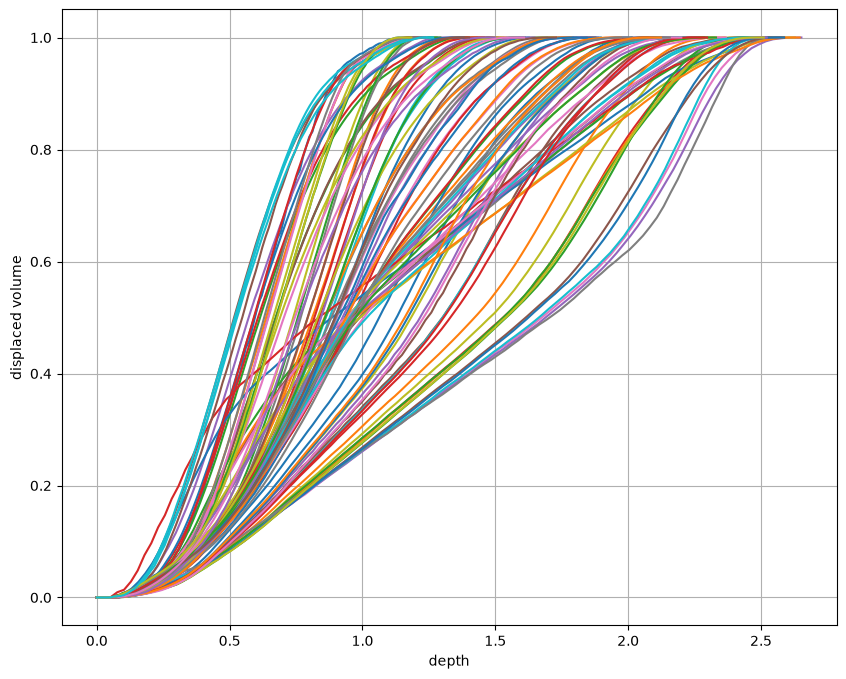

In [55]:
plt.figure(figsize=(10,8))
for dip in dip_output:
    water_h = dip[:, 3]
    vol_h = dip[:, 4]
    plt.plot(water_h - water_h[0] , vol_h)
plt.xlabel("depth") #distance from the initial water height position
plt.ylabel("displaced volume")
plt.grid(True)
plt.show()


In [56]:
dip_output.shape

(100, 100, 5)

In [57]:
"""             
np.full(n_heights, i+1),
np.full(n_heights, theta),
np.full(n_heights, phi),
water_h,
vol_h """

dip_output = dip_output.reshape(-1,5) #flatten to 2D

columns = ["dip no.", "theta", "phi", "water_height_measurement_mm", "displace_vol_mm3"]


np.savetxt("dip_output.csv", dip_output, delimiter=",", header=",".join(columns), comments="", fmt="%.4f" )